# 实验报告02：NumPy、SciPy、Matplotlib 与 pandas 数据处理

| 项目 | 内容 |
|---|---|
| 姓名 | 彭伟明 |
| 学号 | 20244080323 |
| 运行环境 | conda 独立环境 `python-a`（Python 3.12.15） |
| 实验日期 | 2026-10-20 |

本 Notebook 依次完成实验 1～4。每个任务先用 Markdown 说明思路，再用代码单元格完成计算；所有涉及随机抽样的部分都设置了固定种子，保证结果可复现。

## 1.1 第一个代码框：身份与环境记录

该代码框输出当前 conda 环境名、机器指纹与唯一运行 ID。

In [1]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd

# 修改为自己的学号
STUDENT_ID = 20244080323

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "base")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]        {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] python-a
[学号]        20244080323
[机器指纹] 6bba46cdb724809d
[RUN_ID]   20244080323-6bba46cdb724809d


In [2]:
print("NumPy      :", np.__version__)
print("SciPy      :", scipy.__version__)
print("Matplotlib :", matplotlib.__version__)
print("pandas     :", pd.__version__)

NumPy      : 2.5.3
SciPy      : 1.18.1
Matplotlib : 3.11.2
pandas     : 3.0.6


---

## 实验1：NumPy 数组、数据类型与索引

### 1-1 三种数据类型的 ndarray

用 `np.array()` 分别构造整数、浮点和布尔数组，查看 `dtype`、`shape`、`ndim`。再顺带构造一个元素类型混杂的数组，观察 NumPy 如何处理。

In [3]:
int_arr = np.array([1, 2, 3], dtype=np.int64)
float_arr = np.array([1.5, 2.5, 3.5], dtype=np.float64)
bool_arr = np.array([True, False, True], dtype=bool)

for label, arr in [("整数数组", int_arr), ("浮点数组", float_arr), ("布尔数组", bool_arr)]:
    print(f"{label}: {arr}")
    print(f"    dtype={arr.dtype}  shape={arr.shape}  ndim={arr.ndim}")

print()
mixed = np.array([1, 2.5, True])
print("混合列表 np.array([1, 2.5, True]) →", mixed, "dtype =", mixed.dtype)

整数数组: [1 2 3]
    dtype=int64  shape=(3,)  ndim=1
浮点数组: [1.5 2.5 3.5]
    dtype=float64  shape=(3,)  ndim=1
布尔数组: [ True False  True]
    dtype=bool  shape=(3,)  ndim=1

混合列表 np.array([1, 2.5, True]) → [1.  2.5 1. ] dtype = float64


**NumPy 数组与 Python 列表的差别**：

| 对比项 | Python 列表 | NumPy ndarray |
|---|---|---|
| 元素类型 | 可以混杂（int、str、对象都行） | 必须统一，数组只有一个 `dtype`；混合输入会被向上转型（如上面 int、float、bool 统一成 `float64`） |
| 内存布局 | 存的是对象指针，元素分散在堆上 | 连续内存块，每个元素占固定字节数 |
| 运算含义 | `+` 是拼接，其它运算需逐个元素手写循环 | `+`、`*` 等按元素向量化，由 C 循环执行，速度快一两个数量级 |
| 形状 | 没有 `shape`/`ndim` 概念，靠嵌套列表表达 | 有显式的 `shape`、`ndim`，支持多维与广播 |

所以 NumPy 用「类型统一 + 连续内存」换来了向量化运算的性能。

### 1-2 改变形状：reshape

`np.arange(12)` 得到 0～11 共 12 个元素。`reshape` 只改变「怎么看待这块内存」，不复制数据；元素总数必须与目标形状各维乘积相等，否则抛出 `ValueError`。

In [4]:
flat = np.arange(12)
print("一维数组:", flat, "size =", flat.size)

a34 = flat.reshape(3, 4)
a232 = flat.reshape(2, 3, 2)

print()
print("reshape(3, 4):")
print(a34)
print("shape =", a34.shape, " ndim =", a34.ndim)

print()
print("reshape(2, 3, 2):")
print(a232)
print("shape =", a232.shape, " ndim =", a232.ndim)

一维数组: [ 0  1  2  3  4  5  6  7  8  9 10 11] size = 12

reshape(3, 4):
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
shape = (3, 4)  ndim = 2

reshape(2, 3, 2):
[[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]
shape = (2, 3, 2)  ndim = 3


In [5]:
print("元素总数对照：3 × 4 =", 3 * 4, "；2 × 3 × 2 =", 2 * 3 * 2, "；原数组 size =", flat.size)

try:
    flat.reshape(5, 3)
except ValueError as exc:
    print()
    print("reshape(5, 3) 失败 →", type(exc).__name__, ":", exc)

元素总数对照：3 × 4 = 12 ；2 × 3 × 2 = 12 ；原数组 size = 12

reshape(5, 3) 失败 → ValueError : cannot reshape array of size 12 into shape (5,3)


条件就是**新旧形状各维度的乘积必须相等**。`3 × 4 = 12`、`2 × 3 × 2 = 12` 都成立；`5 × 3 = 15 ≠ 12`，所以报错。另一个常见写法 `reshape(3, -1)` 中，`-1` 表示让 NumPy 自己推算这一维。

### 1-3 索引：行、列与布尔索引

对 `(3, 4)` 的数组分别取第 2 行、第 1 至第 3 列、以及大于 6 的元素，并输出各自的形状。

In [6]:
m = np.arange(12).reshape(3, 4)
print("原数组 m:")
print(m)

row2 = m[1]
print()
print("第 2 行 m[1] =", row2, " shape =", row2.shape)

cols13 = m[:, 0:3]
print()
print("第 1 至第 3 列 m[:, 0:3]:")
print(cols13)
print("shape =", cols13.shape)

big = m[m > 6]
print()
print("大于 6 的元素 m[m > 6] =", big, " shape =", big.shape)

原数组 m:
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行 m[1] = [4 5 6 7]  shape = (4,)

第 1 至第 3 列 m[:, 0:3]:
[[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]]
shape = (3, 3)

大于 6 的元素 m[m > 6] = [ 7  8  9 10 11]  shape = (5,)


说明：

- 行、列切片返回的是**视图**，形状随切片范围变化；`m[1]` 把二维降成一维 `(4,)`。
- 布尔索引把满足条件的元素「挑出来」并压平成一维，所以 `m[m > 6]` 的形状是 `(5,)`，而不是原来按行列分布的形状。

### 1-4 组合条件：`|` 与 `&`

`np.arange(10)` 中选出「小于 2 或大于 7」和「大于 3 且小于 7」的元素。注意运算符优先级：`&`、`|` 高于比较运算符，**每个比较式必须用括号括起来**，否则会得到错误的布尔值组合。

In [7]:
x = np.arange(10)
print("x =", x)

mask_or = (x < 2) | (x > 7)
print()
print("(x < 2) | (x > 7)        →", x[mask_or])

mask_and = (x > 3) & (x < 7)
print("(x > 3) & (x < 7)        →", x[mask_and])

print()
print("np.logical_or 结果相同   →", np.array_equal(x[mask_or], x[np.logical_or(x < 2, x > 7)]))
print("np.logical_and 结果相同  →", np.array_equal(x[mask_and], x[np.logical_and(x > 3, x < 7)]))

x = [0 1 2 3 4 5 6 7 8 9]

(x < 2) | (x > 7)        → [0 1 8 9]
(x > 3) & (x < 7)        → [4 5 6]

np.logical_or 结果相同   → True
np.logical_and 结果相同  → True


### 1-5 逐元素乘法与矩阵乘法

构造两个 `(2, 2)` 数组，从运算符和函数两种写法对比如下：

- `*` / `np.multiply()`：**逐元素**相乘，对应位置各自相乘；
- `@` / `np.matmul()`：**矩阵乘法**，结果第 $(i, j)$ 个元素是 A 的第 $i$ 行与 B 的第 $j$ 列的点积。

In [8]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])
print("A =\n", A)
print("B =\n", B)

elem_op = A * B
elem_fn = np.multiply(A, B)
mat_op = A @ B
mat_fn = np.matmul(A, B)

print()
print("逐元素乘法 A * B =\n", elem_op)
print("np.multiply(A, B) 与之相同？", np.array_equal(elem_op, elem_fn))

print()
print("矩阵乘法 A @ B =\n", mat_op)
print("np.matmul(A, B) 与之相同？", np.array_equal(mat_op, mat_fn))

A =
 [[1 2]
 [3 4]]
B =
 [[5 6]
 [7 8]]

逐元素乘法 A * B =
 [[ 5 12]
 [21 32]]
np.multiply(A, B) 与之相同？ True

矩阵乘法 A @ B =
 [[19 22]
 [43 50]]
np.matmul(A, B) 与之相同？ True


两者结果完全不同：`A * B` 的每个元素只是同位相乘（如 `5 = 1 × 5`），而 `A @ B` 的第一行第一列是 `1×5 + 2×7 = 19`。线性代数里的变换、方程组求解必须用 `@`；而加权、逐像素处理等场景用 `*`。

---

## 实验2：随机抽样、统计与缺失值

### 2-1 模拟成绩与截断

用 `np.random.default_rng(20244080323)` 固定种子，生成 1000 个均值 70、标准差 10 的正态随机数，再用 `np.clip(..., 0, 100)` 把超出范围的值压到边界。

In [9]:
rng = np.random.default_rng(20244080323)

raw_scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(raw_scores, 0, 100)

print(f"样本数   : {scores.size}")
print(f"最小值   : {scores.min():.4f}")
print(f"最大值   : {scores.max():.4f}")
print(f"均值     : {scores.mean():.4f}")
print(f"标准差   : {scores.std():.4f}")
print(f"极差     : {scores.max() - scores.min():.4f}")
print(f"被截断的样本数: {np.sum((raw_scores < 0) | (raw_scores > 100))}")

样本数   : 1000
最小值   : 36.5882
最大值   : 100.0000
均值     : 70.0841
标准差   : 10.1199
极差     : 63.4118
被截断的样本数: 2


注意 `clip` 只改动越界的少数样本，因此截断后的均值、方差会与 70、10 略有偏差（截断把极端值「压扁」了）。

### 2-2 不放回抽样：均匀 vs 按大小加权

从 `np.arange(1, 11)` 中不放回地抽 5 个整数：

- 均匀抽样：每个元素被抽中的概率都是 $1/10$，直接 `rng.choice(pop, size=5, replace=False)`；
- 加权抽样：给 `p=` 传入与元素大小成比例的概率向量（这里直接用元素值除以总和），大数更容易被抽中。

`p` 必须与总体等长且总和为 1。

In [10]:
pop = np.arange(1, 11)
weights = pop / pop.sum()

uniform_sample = rng.choice(pop, size=5, replace=False)
weighted_sample = rng.choice(pop, size=5, replace=False, p=weights)

print("总体      :", pop)
print("均匀抽样  :", uniform_sample)
print("加权抽样  :", weighted_sample)
print()
print("加权概率  :", np.round(weights, 4), " 总和 =", weights.sum())
print("均匀抽样期望值 ≈", pop.mean())
print("加权抽样期望值 =", (pop * weights).sum())

总体      : [ 1  2  3  4  5  6  7  8  9 10]
均匀抽样  : [6 7 1 4 2]
加权抽样  : [3 2 5 4 8]

加权概率  : [0.0182 0.0364 0.0545 0.0727 0.0909 0.1091 0.1273 0.1455 0.1636 0.1818]  总和 = 1.0
均匀抽样期望值 ≈ 5.5
加权抽样期望值 = 7.0


In [11]:
# 用大量有放回抽样对比两种分布的平均水平
n_draws = 2000
uniform_many = rng.choice(pop, size=n_draws, replace=True)
weighted_many = rng.choice(pop, size=n_draws, replace=True, p=weights)

print(f"{n_draws} 次有放回抽样的均值：均匀 {uniform_many.mean():.3f}，加权 {weighted_many.mean():.3f}")

2000 次有放回抽样的均值：均匀 5.332，加权 6.979


### 2-3 `permutation()` 与 `shuffle()` 的区别

- `rng.permutation(a)`：返回一个**打乱后的新数组**，原数组不变；
- `rng.shuffle(a)`：**原地**打乱，返回值是 `None`。

In [12]:
base = np.arange(10)
print("操作前 base:", base)

perm = rng.permutation(base)
print()
print("permutation 返回的新数组 perm:", perm)
print("permutation 之后 base 仍是      :", base)

inplace = base.copy()
ret = rng.shuffle(inplace)
print()
print("shuffle 的返回值:", ret, "（None 表示没有返回新数组）")
print("shuffle 之后 inplace:", inplace)

操作前 base: [0 1 2 3 4 5 6 7 8 9]

permutation 返回的新数组 perm: [4 1 0 3 8 5 6 9 7 2]
permutation 之后 base 仍是      : [0 1 2 3 4 5 6 7 8 9]

shuffle 的返回值: None （None 表示没有返回新数组）
shuffle 之后 inplace: [3 5 8 1 6 7 0 9 4 2]


### 2-4 缺失值 `np.nan`

把第 10、20、30 个元素（下标 9、19、29）设为 `np.nan`，对比普通均值和 `nanmean`：

- `np.nan` 参与任何算术运算结果都是 `nan`，所以 `np.mean()`、`np.sum()` 等普通统计函数一旦遇到缺失值，整个结果就变成 `nan`；
- `np.nanmean()`、`np.nansum()` 会先跳过 `nan` 再计算。

In [13]:
scores_nan = scores.copy()
scores_nan[[9, 19, 29]] = np.nan

print("含缺失值的样本数:", scores_nan.size)
print("普通均值 np.mean     :", np.mean(scores_nan))
print("忽略缺失 np.nanmean  :", np.nanmean(scores_nan))
print()
print("缺失值个数:", np.isnan(scores_nan).sum())
print("普通求和 np.sum      :", np.sum(scores_nan))
print("忽略缺失 np.nansum   :", np.nansum(scores_nan))

含缺失值的样本数: 1000
普通均值 np.mean     : nan
忽略缺失 np.nanmean  : 70.06676540404456

缺失值个数: 3
普通求和 np.sum      : nan
忽略缺失 np.nansum   : 69856.56510783243


`nan` 会「传染」：只要参与运算的数里有一个 `nan`，结果就是 `nan`。这是 IEEE 754 的规定，用来提醒调用方数据不完整，而不是悄悄算出一个错误答案。因此真实数据处理中要么先 `fillna`／删除缺失值，要么使用 `nan` 系列函数。

### 2-5 把含缺失值的成绩整理成内存表格

只构造 DataFrame 变量留在内存中，不写任何文件，供实验4直接使用。

In [14]:
scores_table = pd.DataFrame({
    "序号": np.arange(1, scores_nan.size + 1),
    "成绩": scores_nan,
})

print("shape:", scores_table.shape)
print(scores_table.head())
print()
print("缺失值个数:", scores_table["成绩"].isna().sum())

shape: (1000, 2)
   序号         成绩
0   1  71.633597
1   2  67.587960
2   3  53.689851
3   4  58.202521
4   5  81.634349

缺失值个数: 3


---

## 实验3：SciPy 数值计算与 Matplotlib 可视化

### 3-1 用 `scipy.linalg.solve()` 解线性方程组

方程组

$$3x + y = 9,\qquad x + 2y = 8$$

写成矩阵形式 $A\mathbf{x} = \mathbf{b}$，其中 $A = \begin{bmatrix}3 & 1\\ 1 & 2\end{bmatrix}$，$\mathbf{b} = \begin{bmatrix}9\\ 8\end{bmatrix}$。求出解后再代回原方程验证。

In [15]:
from scipy.linalg import solve

A = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([9.0, 8.0])

solution = solve(A, b)
print("解 x =", solution)
print()
print("代入 A @ x =", A @ solution, "，与原 b =", b, "接近？", np.allclose(A @ solution, b))
print("残差范数 =", np.linalg.norm(A @ solution - b))

解 x = [2. 3.]

代入 A @ x = [9. 8.] ，与原 b = [9. 8.] 接近？ True
残差范数 = 1.7763568394002505e-15


### 3-2 用 `scipy.optimize.root()` 求 $x^2 - 2 = 0$ 的根

`root()` 是局部求根，结果取决于初始猜测。分别用 `x0 = 1` 和 `x0 = -1`，应分别收敛到 $+\sqrt{2}$ 和 $-\sqrt{2}$。`success` 表示求解是否正常结束，`f(res.x)` 应接近 0。

In [16]:
from scipy.optimize import root

def f(x):
    return x ** 2 - 2

for guess in (1.0, -1.0):
    res = root(f, guess)
    value = res.x[0]
    fval = f(res.x)[0]
    print(f"初始猜测 {guess:>5}: success={res.success}, x={value:.10f}, f(x)={fval:.3e}, |f(x)| 接近 0？{np.isclose(fval, 0)}")

print()
print("参考：np.sqrt(2) =", np.sqrt(2))

初始猜测   1.0: success=True, x=1.4142135624, f(x)=-8.882e-16, |f(x)| 接近 0？True
初始猜测  -1.0: success=True, x=-1.4142135624, f(x)=-8.882e-16, |f(x)| 接近 0？True

参考：np.sqrt(2) = 1.4142135623730951


初始猜测的正负决定了收敛到哪一侧的根，说明求根问题可能有多个解、算法只保证找到「离初值最近」的那个。

### 3-3 用 `minimize()` 求 $f(x) = x^2 + x + 2$ 的最小值

解析解：$f'(x) = 2x + 1 = 0 \Rightarrow x = -0.5$，最小值 $f(-0.5) = 0.25 - 0.5 + 2 = 1.75$。

In [17]:
from scipy.optimize import minimize

def g(x):
    return x[0] ** 2 + x[0] + 2

res = minimize(g, x0=0.0)

print("success     :", res.success)
print("极小点 x*   :", f"{res.x[0]:.6f}")
print("最小值 f(x*):", f"{res.fun:.6f}")
print()
print("解析解对照  : x = -0.5, f = 1.75")
print("误差        :", f"{abs(res.x[0] + 0.5):.2e}")

success     : True
极小点 x*   : -0.500000
最小值 f(x*): 1.750000

解析解对照  : x = -0.5, f = 1.75
误差        : 6.43e-09


### 3-4 独立样本 t 检验

两组独立样本，各 100 个观测，分别来自 $N(0, 1)$ 和 $N(1, 1)$，固定种子后调用 `ttest_ind()`。

原假设 $H_0$：两组均值相等。若 p 值小于显著性水平 0.05，则拒绝 $H_0$，认为两组均值存在显著差异。

In [18]:
from scipy.stats import ttest_ind

rng_t = np.random.default_rng(20244080323)
group_a = rng_t.normal(loc=0.0, scale=1.0, size=100)
group_b = rng_t.normal(loc=1.0, scale=1.0, size=100)

stat, p_value = ttest_ind(group_a, group_b)
alpha = 0.05

print(f"第一组均值 = {group_a.mean():.4f}")
print(f"第二组均值 = {group_b.mean():.4f}")
print(f"t 统计量   = {stat:.4f}")
print(f"p 值       = {p_value:.3e}")
print()
print(f"p < {alpha} ？{p_value < alpha}")
print("结论：" + ("拒绝原假设，两组均值差异显著。" if p_value < alpha else "不能拒绝原假设，差异不显著。"))

第一组均值 = -0.0219
第二组均值 = 1.0439
t 统计量   = -8.1454
p 值       = 4.183e-14

p < 0.05 ？True
结论：拒绝原假设，两组均值差异显著。


### 3-5 可视化

三张图：

1. 实验2 中**有效成绩**（去掉 `nan`）的直方图；
2. 同一批成绩的箱线图；
3. $y = x$、$y = x^2$、$y = x^3$ 在 $0 \le x \le 5$ 上的折线图，三条线在同一坐标系并配图例。

每张图都有标题和坐标轴标签，图像直接内嵌显示。

In [19]:
%matplotlib inline
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

valid_scores = scores_nan[~np.isnan(scores_nan)]
print("有效成绩个数:", valid_scores.size)

有效成绩个数: 997


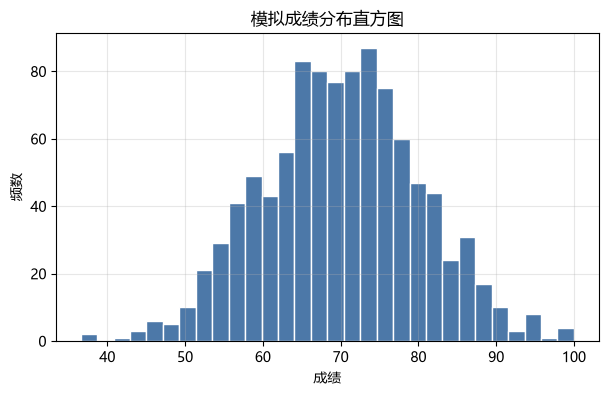

In [20]:
plt.figure(figsize=(7, 4))
plt.hist(valid_scores, bins=30, color="#4C78A8", edgecolor="white")
plt.title("模拟成绩分布直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.grid(alpha=0.3)
plt.show()

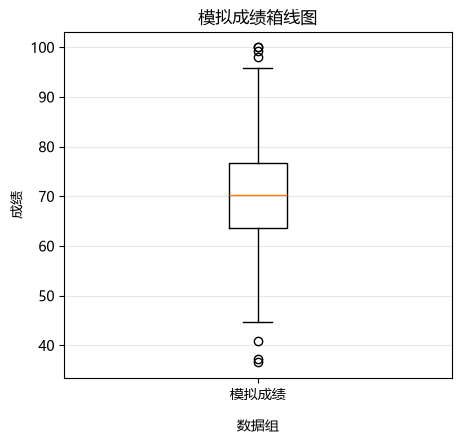

In [21]:
plt.figure(figsize=(5, 4.5))
plt.boxplot(valid_scores, tick_labels=["模拟成绩"])
plt.title("模拟成绩箱线图")
plt.xlabel("数据组", labelpad=12)
plt.ylabel("成绩")
plt.grid(alpha=0.3, axis="y")
plt.show()

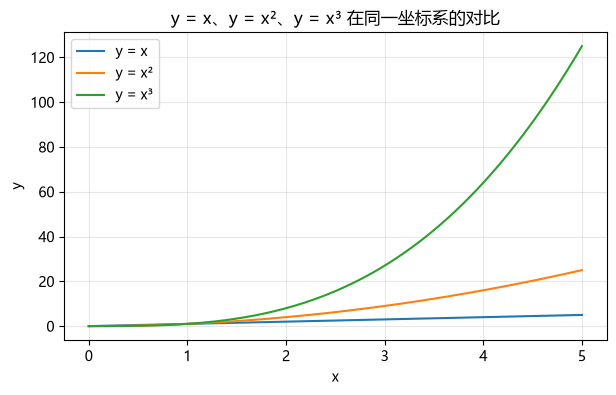

In [22]:
x = np.linspace(0, 5, 200)

plt.figure(figsize=(7, 4))
plt.plot(x, x, label="y = x")
plt.plot(x, x ** 2, label="y = x²")
plt.plot(x, x ** 3, label="y = x³")
plt.title("y = x、y = x²、y = x³ 在同一坐标系的对比")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

从直方图看，成绩近似正态地集中在 60～80 附近，只有 2 个样本被截断到 100，对整体形状影响很小；箱线图显示中位数约 70，四分位区间约 63～76，上下各有一些离群点。折线图则直观显示出三条曲线随 x 增大而拉开：在 $0 \le x \le 1$ 时 $x \ge x^2 \ge x^3$，$x > 1$ 后大小关系反转，增长最快的变成 $x^3$。

---

## 实验4：pandas Series、DataFrame 与内存中的 CSV 读写

### 4-1 创建 DataFrame 并计算总分、平均分

用给定的模拟数据建表，以 `Name` 作为行索引，新增 `Total`（三科总分）与 `Average`（三科平均分）两列，然后查看行索引、列名、前 3 行与基本统计信息。

In [23]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

subjects = ["Math", "English", "Python"]

df = pd.DataFrame(records).set_index("Name")
df["Total"] = df[subjects].sum(axis=1)
df["Average"] = df[subjects].mean(axis=1)

pd.set_option("display.float_format", "{:.2f}".format)

print("行索引:", list(df.index))
print("列名  :", list(df.columns))
print()
print("前 3 行:")
print(df.head(3))
print()
print("基本统计信息:")
print(df[subjects + ["Total", "Average"]].describe())

行索引: ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名  : ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行:
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Bob       A    72       68      80    220    73.33
Carol     B    91       85      89    265    88.33

基本统计信息:
       Math  English  Python  Total  Average
count  6.00     6.00    6.00   6.00     6.00
mean  79.83    80.83   83.67 244.33    81.44
std    9.91     9.66    8.55  25.78     8.59
min   65.00    68.00   70.00 208.00    69.33
25%   73.75    74.00   80.50 225.75    75.25
50%   81.50    81.00   84.00 250.00    83.33
75%   87.00    88.75   88.25 263.00    87.67
max   91.00    92.00   95.00 273.00    91.00


### 4-2 `loc` 与 `iloc` 读取、按条件筛选

- `loc` 按**标签**（姓名）索引：`df.loc["Carol"]`；
- `iloc` 按**位置**索引：Carol 是第 3 行，位置下标为 2，`df.iloc[2]`。

两者取到的是同一条记录。筛选平均分不低于 80 的学生，用布尔索引 `df[df["Average"] >= 80]`。

In [24]:
carol_loc = df.loc["Carol"]
carol_iloc = df.iloc[2]

print("df.loc['Carol']:")
print(carol_loc)
print()
print("df.iloc[2]:")
print(carol_iloc)
print()
print("两种方式结果相同？", carol_loc.equals(carol_iloc))

df.loc['Carol']:
Group         B
Math         91
English      85
Python       89
Total       265
Average   88.33
Name: Carol, dtype: object

df.iloc[2]:
Group         B
Math         91
English      85
Python       89
Total       265
Average   88.33
Name: Carol, dtype: object

两种方式结果相同？ True


In [25]:
print("平均分 >= 80 的学生:")
print(df[df["Average"] >= 80])

平均分 >= 80 的学生:
      Group  Math  English  Python  Total  Average
Name                                              
Alice     A    88       90      95    273    91.00
Carol     B    91       85      89    265    88.33
Eva       A    79       92      86    257    85.67
Frank     B    84       77      82    243    81.00


### 4-3 列均值与行均值：`axis` 的含义

`mean(axis=0)` 沿 **0 轴**（跨行、对每一列）求平均，得到三科的列均值；`mean(axis=1)` 沿 **1 轴**（跨列、对每一行）求平均，得到每名学生的行均值，也就是 `Average` 列。

In [26]:
col_mean = df[subjects].mean(axis=0)
row_mean = df[subjects].mean(axis=1)

print("每科的列均值 mean(axis=0):")
print(col_mean.round(3))
print()
print("每名学生的行均值 mean(axis=1):")
print(row_mean.round(3))
print()
print("行均值与 Average 列一致？", np.allclose(row_mean, df["Average"]))

每科的列均值 mean(axis=0):
Math      79.83
English   80.83
Python    83.67
dtype: float64

每名学生的行均值 mean(axis=1):
Name
Alice   91.00
Bob     73.33
Carol   88.33
David   69.33
Eva     85.67
Frank   81.00
dtype: float64

行均值与 Average 列一致？ True


### 4-4 `apply()`、`agg()` 与 `rank()`

- `apply(np.max, axis=1)` 对每一行应用函数，得到每人三科最高分；
- `agg(["min", "mean", "max"])` 一次得到每科的三个统计量；
- `rank(ascending=False)` 对 Python 成绩排名，分数越高名次越靠前。

In [27]:
best = df[subjects].apply(np.max, axis=1)
print("每名学生三科最高分:")
print(best)
print()
print("每科 min / mean / max:")
print(df[subjects].agg(["min", "mean", "max"]).round(2))
print()
print("Python 成绩排名（1 为最高）:")
print(df["Python"].rank(ascending=False, method="min").astype(int))

每名学生三科最高分:
Name
Alice    95
Bob      80
Carol    91
David    73
Eva      92
Frank    84
dtype: int64

每科 min / mean / max:
      Math  English  Python
min  65.00    68.00   70.00
mean 79.83    80.83   83.67
max  91.00    92.00   95.00

Python 成绩排名（1 为最高）:
Name
Alice    1
Bob      5
Carol    2
David    6
Eva      3
Frank    4
Name: Python, dtype: int64


### 4-5 分组统计与 `transform`

按 `Group` 分组：`size()` 数人数，`mean()` 求各科均值。`transform("mean")` 把每组的均值**广播回原表的每一行**，所以可以新增一列「本组 Python 平均分」而不改变行数。

In [28]:
group_counts = df.groupby("Group").size()
group_means = df.groupby("Group")[subjects].mean().round(2)

print("每组人数:")
print(group_counts)
print()
print("每组三科平均分:")
print(group_means)

df["GroupPythonMean"] = df.groupby("Group")["Python"].transform("mean")
print()
print("每行所在组的 Python 平均分:")
print(df[["Group", "Python", "GroupPythonMean"]])

每组人数:
Group
A    3
B    3
dtype: int64

每组三科平均分:
       Math  English  Python
Group                       
A     79.67    83.33   87.00
B     80.00    78.33   80.33

每行所在组的 Python 平均分:
      Group  Python  GroupPythonMean
Name                                
Alice     A      95            87.00
Bob       A      80            87.00
Carol     B      89            80.33
David     B      70            80.33
Eva       A      86            87.00
Frank     B      82            80.33


### 4-6 `groupby().filter()` 按组筛选

`filter()` 的作用对象是**组**：传入的函数接收整组数据，返回 True/False 决定整组是否保留。这里保留 Python 平均分不低于 80 的组。再补一个阈值 85 的对照，展示筛选确实会剔除整组。

In [29]:
kept = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 80)
print("阈值 80：保留的组 =", sorted(kept["Group"].unique()))
print(kept[["Group", "Python"]])

kept_85 = df.groupby("Group").filter(lambda g: g["Python"].mean() >= 85)
print()
print("阈值 85：保留的组 =", sorted(kept_85["Group"].unique()))
print(kept_85[["Group", "Python"]])

阈值 80：保留的组 = ['A', 'B']
      Group  Python
Name               
Alice     A      95
Bob       A      80
Carol     B      89
David     B      70
Eva       A      86
Frank     B      82

阈值 85：保留的组 = ['A']
      Group  Python
Name               
Alice     A      95
Bob       A      80
Eva       A      86


### 4-7 协方差矩阵与相关系数矩阵

- 协方差 $\mathrm{cov}(X, Y)$ 衡量两个变量的共同变化方向，**符号**表示正相关还是负相关，但数值受量纲影响；
- 皮尔森相关系数 $r = \dfrac{\mathrm{cov}(X,Y)}{\sigma_X \sigma_Y}$，把协方差归一化到 $[-1, 1]$，只看**方向和强度**：$|r|$ 越接近 1 线性关系越强，接近 0 表示几乎没有线性关系。

In [30]:
cov_matrix = df[subjects].cov().round(2)
corr_matrix = df[subjects].corr().round(3)

print("协方差矩阵:")
print(cov_matrix)
print()
print("皮尔森相关系数矩阵:")
print(corr_matrix)

协方差矩阵:
         Math  English  Python
Math    98.17    62.57   74.93
English 62.57    93.37   62.53
Python  74.93    62.53   73.07

皮尔森相关系数矩阵:
         Math  English  Python
Math     1.00     0.65    0.89
English  0.65     1.00    0.76
Python   0.89     0.76    1.00


**以 Math 与 Python 这一对为例**：协方差为 74.93（正数），说明两科成绩同向变化；相关系数为 0.89，绝对值接近 1，属于强正相关——数学好的学生 Python 成绩往往也好。相比之下 Math 与 English 的协方差 62.57 虽也不小，但相关系数只有 0.65，线性关联明显弱于前者。这正体现了协方差受各自方差大小影响、而相关系数把尺度归一化后更适合跨变量比较。

---

## 实验小结

| 实验 | 内容 | 关键结论 |
|---|---|---|
| 1 | NumPy 数组、形状、索引 | ndarray 类型统一、内存连续；reshape 要求元素总数不变；布尔索引压平为一维 |
| 2 | 随机抽样、统计、缺失值 | `default_rng` 固定种子可复现；`permutation` 返回副本、`shuffle` 原地；`nan` 会传播，需用 `nanmean` |
| 3 | SciPy 求解与绘图 | `solve` 解方程组、`root` 依赖初值、`minimize` 与解析解一致；t 检验 p < 0.05 判定差异显著；图表需标题、轴标签、图例 |
| 4 | pandas 数据处理 | `loc`/`iloc` 按标签/位置；`axis` 决定按行还是按列；`transform` 广播组均值；`filter` 按组筛选；相关系数比协方差更便于比较 |